# 39 — Style proof sheet

One page with one example of every chart type, drawn in the thesis style at the printed size, on the real labelled dataset. Look at it, ask for changes; the changes go into `viz/style.py` / `viz/plots.py` once, and every figure of notebooks 40–44 follows.

Writes `<output>/style/proof_sheet.pdf` and `.png`. The numbers here are only illustrations of the style.

In [1]:
import sys, pathlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import binomtest
from viz import config, data, style, plots
cfg = config.load()
style.apply(cfg)
ds = data.load_dataset(cfg)

## The data used for the illustrations

One row per aircraft: class, priority year, window, region.

In [2]:
idt = ds.identity[['patent_id', 'priority_year', 'region']].drop_duplicates('patent_id')
a = ds.variants[['aircraft_id', 'patent_id', 'topType']].merge(idt, on='patent_id', how='left')
a['year'] = pd.to_numeric(a['priority_year'], errors='coerce')
W = cfg.analysis['windows']
def window(y):
    return next((k for k, (lo, hi) in W.items() if lo <= y <= hi), None) if pd.notna(y) else None
a['window'] = a['year'].map(window)
a = a.dropna(subset=['topType', 'window'])
a.head()

,aircraft_id,patent_id,topType,priority_year,region,year,window
0,US2021331794A1_ua1,US2021331794A1,TR,2018,North America,2018,2016-19
1,US2023056709A1_ua1,US2023056709A1,MR,2020,Asia-Pacific,2020,2020-23
2,US2023056709A1_ua2,US2023056709A1,MR,2020,Asia-Pacific,2020,2020-23
3,US2018244367A1_ua1,US2018244367A1,MR,2017,Europe,2017,2016-19
4,US2018265189A1_ua1,US2018265189A1,MR,2017,Europe,2017,2016-19


## The proof sheet

written /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/style/proof_sheet.pdf


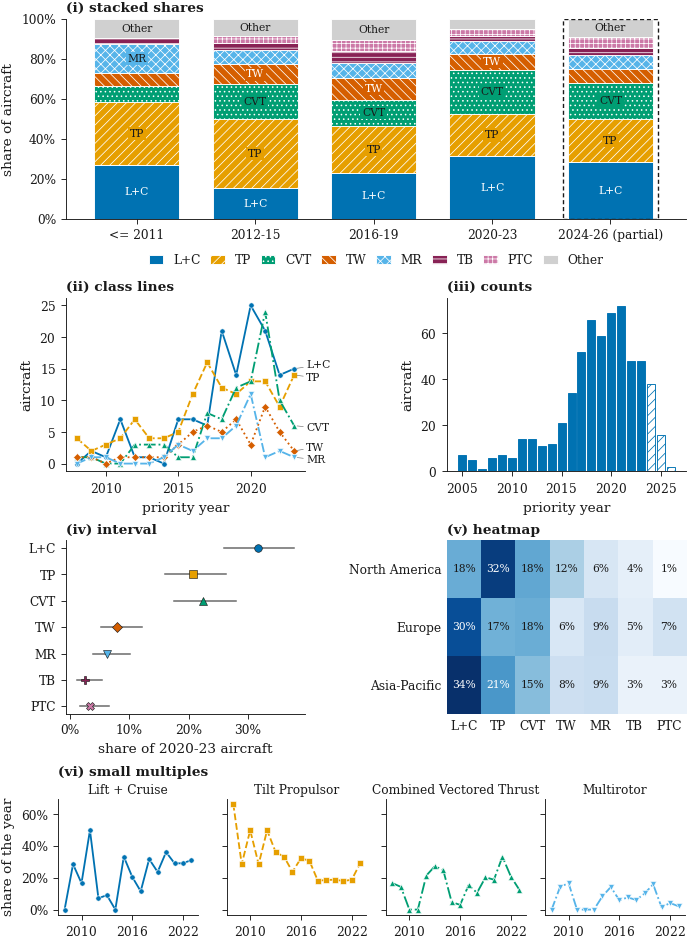

In [3]:
big = ['SLC', 'TR', 'CVT', 'TW', 'MR', 'TB', 'PTC']
a['cls'] = a['topType'].where(a['topType'].isin(big), 'Other')
w, _ = style.size(cfg, 'full')
fig = plt.figure(figsize=(w, 8.6), constrained_layout=True)
g = fig.add_gridspec(4, 2, height_ratios=[1.15, 1, 1, 1.05])

# (i) stacked shares per window
ax = fig.add_subplot(g[0, :])
sh = pd.crosstab(a['window'], a['cls'], normalize='index').reindex(list(W))
plots.share_bars(ax, sh, partial=[k for k in W if 'partial' in k])
ax.set_ylabel('share of aircraft'); style.mark(ax, '(i) stacked shares')
ax.legend(ncol=8, loc='upper center', bbox_to_anchor=(0.5, -0.12), handlelength=1.2, columnspacing=0.8)

# (ii) class lines over priority years
ax = fig.add_subplot(g[1, 0])
yr = a[a['year'].between(2008, 2023)]
lines = pd.crosstab(yr['year'], yr['topType'])[['SLC', 'TR', 'CVT', 'TW', 'MR']]
plots.class_lines(ax, lines)
ax.set_ylabel('aircraft'); ax.set_xlabel('priority year'); style.mark(ax, '(ii) class lines')

# (iii) counts per year, partial years hatched
ax = fig.add_subplot(g[1, 1])
cnt = a[a['year'] >= 2005]['year'].value_counts().sort_index()
plots.count_bars(ax, cnt.index.astype(int), cnt.values, partial_from=cfg.analysis['partial_window_start'])
ax.set_ylabel('aircraft'); ax.set_xlabel('priority year'); style.mark(ax, '(iii) counts')

# (iv) shares with a 95 % interval (Wilson)
ax = fig.add_subplot(g[2, 0])
rec = a[a['window'].eq('2020-23')]
k = rec['topType'].value_counts().reindex(big).fillna(0).astype(int); n = len(rec)
ci = [binomtest(int(x), n).proportion_ci(method='wilson') for x in k]
plots.ci_bars(ax, [style.cls(c).short for c in big], k / n, [c.low for c in ci], [c.high for c in ci], codes=big)
ax.set_xlabel('share of 2020-23 aircraft'); style.mark(ax, '(iv) interval')

# (v) heatmap: class mix per region
ax = fig.add_subplot(g[2, 1])
hm = pd.crosstab(a['region'], a['cls'], normalize='index')
hm = hm[[c for c in big if c in hm.columns]].reindex(['North America', 'Europe', 'Asia-Pacific']).dropna(how='all')
hm.columns = [style.cls(c).short for c in hm.columns]
plots.heatmap(ax, hm); style.mark(ax, '(v) heatmap')

# (vi) small multiples: one class per panel
sub = g[3, :].subgridspec(1, 4, wspace=0.08)
share_max = None
share_y = pd.crosstab(yr['year'], yr['topType'], normalize='index')
for i, c in enumerate(['SLC', 'TR', 'CVT', 'MR']):
    ax = fig.add_subplot(sub[0, i], sharey=None if i == 0 else fig.axes[-1])
    plots.class_lines(ax, share_y[[c]], pct=True, end_labels=False)
    ax.set_title(style.cls(c).name, fontsize=plt.rcParams['xtick.labelsize'], pad=3)
    ax.set_xticks([2010, 2016, 2022])
    if i: ax.tick_params(labelleft=False)
    else: ax.set_ylabel('share of the year'); style.mark(ax, '(vi) small multiples', lines_up=1)

out = cfg.out('style')
fig.savefig(out / 'proof_sheet.pdf'); fig.savefig(out / 'proof_sheet.png')
print('written', out / 'proof_sheet.pdf')

## The class scheme

Every class keeps this colour, marker, dash and hatch in every figure.

In [4]:
pd.DataFrame([dict(code=s.code, printed=s.short, name=s.name, colour=s.color, marker=s.marker, dash=str(s.dash), hatch=s.hatch) for s in style.CLASSES.values()])

,code,printed,name,colour,marker,dash,hatch
0,SLC,L+C,Lift + Cruise,#0072B2,o,-,
1,TR,TP,Tilt Propulsor,#E69F00,s,--,////
2,CVT,CVT,Combined Vectored Thrust,#009E73,^,-.,....
3,TW,TW,Tilt Wing,#D55E00,D,:,\\\\
4,MR,MR,Multirotor,#56B4E9,v,"(0, (5, 1.5, 1, 1.5))",xxxx
5,TB,TB,Tilt Body,#882255,P,"(0, (1, 1))",----
6,PTC,PTC,Pitch-to-Cruise,#CC79A7,X,"(0, (8, 2))",++++
7,RC,RC,Rotorcraft,#4d4d4d,h,-,
8,SRW,SRW,Stopped/Slowed Rotor Wing,#7a7a7a,<,--,oo
9,DS,DS,Deflected Slipstream,#a6a6a6,>,:,..
